<a href="https://colab.research.google.com/github/jeeneshwaar-1/Deep_learning-Project/blob/main/Copy_of_Untitled4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("TensorFlow version:", tf.__version__)

NumPy version: 2.1.3
Pandas version: 2.2.3
TensorFlow version: 2.21.0


In [ ]:
from tensorflow.keras.datasets import imdb

# Load the movie-review dataset
(x_train, y_train), (x_test, y_test) = imdb.load_data(
    num_words=10000
)

print("Training reviews:", len(x_train))
print("Testing reviews:", len(x_test))

print("First review:", x_train[0])
print("Sentiment label:", y_train[0])

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training reviews: 25000
Testing reviews: 25000
First review: [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50, 670, 2, 9, 35, 480, 284, 5, 150, 4, 172, 112, 167, 2, 336, 385, 39, 4, 172, 4536, 1111, 17, 546, 38, 13, 447, 4, 192, 50, 16, 6, 147, 2025, 19, 14, 22, 4, 1920, 4613, 469, 4, 22, 71, 87, 12, 16, 43, 530, 38, 76, 15, 13, 1247, 4, 22, 17, 515, 17, 12, 16, 626, 18, 2, 5, 62, 386, 12, 8, 316, 8, 106, 5, 4, 2223, 5244, 16, 480, 66, 3785, 33, 4, 130, 12, 16, 38, 619, 5, 25, 124, 51, 36, 135, 48, 25, 1415, 33, 6, 22, 12, 215, 28, 77, 52, 5, 14, 407, 16, 82, 2, 8, 4, 107, 117, 5952, 15, 256, 4, 2, 7, 3766, 5, 723, 36, 71, 43, 530, 476, 26, 400, 317, 46, 7, 4, 2, 1029, 13, 104, 88, 4, 381, 15, 297, 98, 32, 2071, 56, 26, 141, 6, 194, 7486, 18, 4, 226, 22, 21, 134, 476, 26, 480, 5, 144, 30, 5535, 18, 51, 36, 28, 224, 92, 25, 104, 4, 226, 65, 16, 38, 1334, 88, 12, 16, 283, 5,

Sentiment distribution:
Negative reviews (0): 12500
Positive reviews (1): 12500


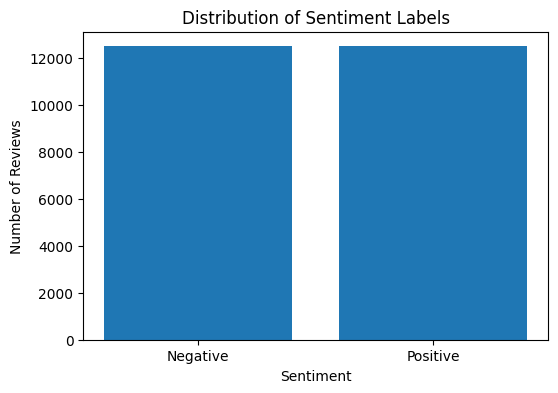

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Convert sentiment labels into a table
sentiment_counts = pd.Series(y_train).value_counts().sort_index()

print("Sentiment distribution:")
print("Negative reviews (0):", sentiment_counts[0])
print("Positive reviews (1):", sentiment_counts[1])

# Visualize the distribution
plt.figure(figsize=(6, 4))
plt.bar(
    ["Negative", "Positive"],
    [sentiment_counts[0], sentiment_counts[1]]
)
plt.title("Distribution of Sentiment Labels")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()

Shortest review: 11 tokens
Longest review: 2494 tokens
Average review length: 238.71


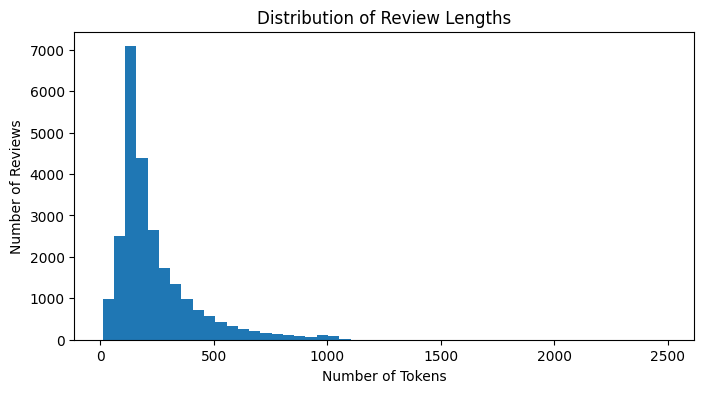

In [ ]:
# Calculate the number of tokens in each review
review_lengths = [len(review) for review in x_train]

print("Shortest review:", min(review_lengths), "tokens")
print("Longest review:", max(review_lengths), "tokens")
print("Average review length:", round(sum(review_lengths) / len(review_lengths), 2))

# Plot the distribution
plt.figure(figsize=(8, 4))
plt.hist(review_lengths, bins=50)
plt.title("Distribution of Review Lengths")
plt.xlabel("Number of Tokens")
plt.ylabel("Number of Reviews")
plt.show()

In [ ]:
# Obtain the word-to-number mapping
word_index = imdb.get_word_index()

# Reverse the mapping: number to word
index_word = {
    index + 3: word
    for word, index in word_index.items()
}

# Special tokens used by the dataset
index_word[0] = "<PAD>"
index_word[1] = "<START>"
index_word[2] = "<UNKNOWN>"
index_word[3] = "<UNUSED>"

# Decode the first review
decoded_review = " ".join(
    index_word.get(token, "<UNKNOWN>")
    for token in x_train[0]
)

print("Decoded review:")
print(decoded_review)

print("\nSentiment label:", y_train[0])

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Decoded review:
<START> this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert <UNKNOWN> is an amazing actor and now the same being director <UNKNOWN> father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for <UNKNOWN> and would recommend it to everyone to watch and the fly fishing was amazing really cried at the end it was so sad and you know what they say if you cry at a film it must have been good and this definitely was also <UNKNOWN> to the two little boy's that played the <UNKNOWN> of norman and paul they were just brilliant children are often left out of the <UNKNOWN> list i think because the stars that play them all grown up are such a bi

In [ ]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Define the maximum review length
maximum_length = 200

# Apply padding and truncation
x_train_padded = pad_sequences(
    x_train,
    maxlen=maximum_length,
    padding="post",
    truncating="post"
)

x_test_padded = pad_sequences(
    x_test,
    maxlen=maximum_length,
    padding="post",
    truncating="post"
)

# Display the results
print("Original review length:", len(x_train[0]))
print("Processed review length:", len(x_train_padded[0]))

print("\nOriginal review:")
print(x_train[0])

print("\nProcessed review:")
print(x_train_padded[0])

print("\nTraining data shape:", x_train_padded.shape)
print("Testing data shape:", x_test_padded.shape)

Original review length: 218
Processed review length: 200

Original review:
[1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50, 670, 2, 9, 35, 480, 284, 5, 150, 4, 172, 112, 167, 2, 336, 385, 39, 4, 172, 4536, 1111, 17, 546, 38, 13, 447, 4, 192, 50, 16, 6, 147, 2025, 19, 14, 22, 4, 1920, 4613, 469, 4, 22, 71, 87, 12, 16, 43, 530, 38, 76, 15, 13, 1247, 4, 22, 17, 515, 17, 12, 16, 626, 18, 2, 5, 62, 386, 12, 8, 316, 8, 106, 5, 4, 2223, 5244, 16, 480, 66, 3785, 33, 4, 130, 12, 16, 38, 619, 5, 25, 124, 51, 36, 135, 48, 25, 1415, 33, 6, 22, 12, 215, 28, 77, 52, 5, 14, 407, 16, 82, 2, 8, 4, 107, 117, 5952, 15, 256, 4, 2, 7, 3766, 5, 723, 36, 71, 43, 530, 476, 26, 400, 317, 46, 7, 4, 2, 1029, 13, 104, 88, 4, 381, 15, 297, 98, 32, 2071, 56, 26, 141, 6, 194, 7486, 18, 4, 226, 22, 21, 134, 476, 26, 480, 5, 144, 30, 5535, 18, 51, 36, 28, 224, 92, 25, 104, 4, 226, 65, 16, 38, 1334, 88, 12, 16, 283, 5, 16, 4472, 113, 103, 32, 15, 16, 5345

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

# Define model parameters
vocabulary_size = 10000
embedding_dimension = 64
maximum_length = 200

# Build the deep learning model
model = Sequential([
    Embedding(
        input_dim=vocabulary_size,
        output_dim=embedding_dimension,
        mask_zero=True
    ),

    LSTM(64),

    Dropout(0.5),

    Dense(1, activation="sigmoid")
])

# Display the model architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

vocabulary_size = 10000
embedding_dimension = 64
maximum_length = 200

model = Sequential([
    tf.keras.Input(shape=(maximum_length,)),

    Embedding(
        input_dim=vocabulary_size,
        output_dim=embedding_dimension,
        mask_zero=True
    ),

    LSTM(64),

    Dropout(0.5),

    Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 673,089 (2.57 MB)

 Trainable params: 673,089 (2.57 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [ ]:
history = model.fit(
    x_train_padded,
    y_train,
    epochs=3,
    batch_size=64,
    validation_split=0.2
)

Epoch 1/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 76s 235ms/step - accuracy: 0.7664 - loss: 0.4808 - val_accuracy: 0.8280 - val_loss: 0.4187
Epoch 2/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 77s 221ms/step - accuracy: 0.8845 - loss: 0.3018 - val_accuracy: 0.8614 - val_loss: 0.3676
Epoch 3/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 67s 215ms/step - accuracy: 0.9183 - loss: 0.2260 - val_accuracy: 0.8658 - val_loss: 0.3604


In [ ]:
# Evaluate the trained model on unseen test reviews
test_loss, test_accuracy = model.evaluate(
    x_test_padded,
    y_test,
    verbose=1
)

print("\nTest Results")
print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

782/782 ━━━━━━━━━━━━━━━━━━━━ 31s 40ms/step - accuracy: 0.8460 - loss: 0.3953

Test Results
Test Loss: 0.3953
Test Accuracy: 84.6 %


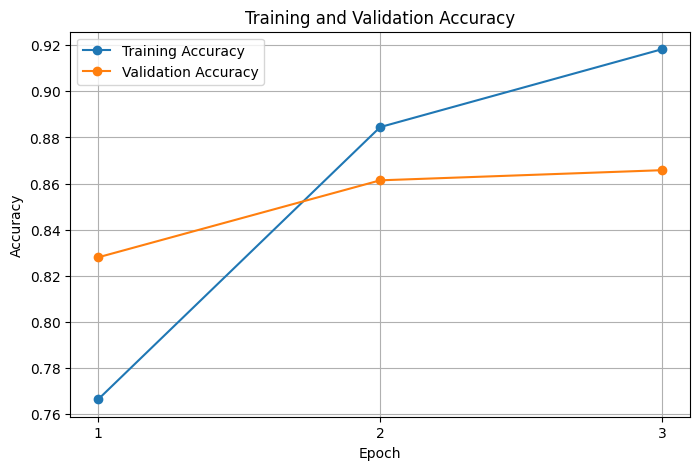

In [ ]:
import matplotlib.pyplot as plt

# Plot training and validation accuracy
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks([0, 1, 2], ["1", "2", "3"])
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
test_loss, test_accuracy = model.evaluate(
    x_test_padded,
    y_test,
    verbose=1
)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

782/782 ━━━━━━━━━━━━━━━━━━━━ 32s 41ms/step - accuracy: 0.8460 - loss: 0.3953
Test Loss: 0.3953
Test Accuracy: 84.6 %


In [ ]:
import numpy as np

def predict_sentiment(review):
    # Convert words into the dataset's numerical representation
    words = review.lower().split()

    encoded_review = [1]

    for word in words:
        word_id = word_index.get(word, 0) + 3

        if word_id >= 10000:
            word_id = 2

        encoded_review.append(word_id)

    # Pad the review to the required length
    padded_review = pad_sequences(
        [encoded_review],
        maxlen=200,
        padding="post",
        truncating="post"
    )

    # Predict sentiment
    prediction = model.predict(padded_review, verbose=0)[0][0]

    if prediction >= 0.5:
        sentiment = "Positive"
    else:
        sentiment = "Negative"

    print("Review:", review)
    print("Predicted sentiment:", sentiment)
    print("Positive sentiment score:", round(float(prediction), 4))


predict_sentiment("This movie was absolutely fantastic and entertaining")

Review: This movie was absolutely fantastic and entertaining
Predicted sentiment: Positive
Positive sentiment score: 0.8405
